In [ ]:
import joblib
import os
import glob

# Load all saved models
models_dir = 'models'
model_files = glob.glob(os.path.join(models_dir, '*_compression_model.pkl'))

loaded_results = {}

print("Loading saved models...")
print("=" * 70)

for model_path in model_files:
    # Extract the model name from the file name
    model_filename = os.path.basename(model_path)
    # Remove '_compression_model.pkl' and replace underscores with spaces
    model_name = model_filename.replace('_compression_model.pkl', '').replace('_', ' ').title()
    
    # Load only Random Forest
    if model_name != 'Random Forest':
        continue
    
    # Load model
    model = joblib.load(model_path)
    loaded_results[model_name] = {'model': model}
    
    print(f"Loaded: {model_name}")
    print(f"File: {model_filename}")
    print(f"  Type: {type(model).__name__}")
    print()

print(f"\nA total of {len(loaded_results)} models were loaded")
print("=" * 70)


Wczytywanie zapisanych modeli...
Wczytano: Random Forest
Plik: random_forest_compression_model.pkl
  Typ: RandomForestRegressor


Łącznie wczytano 1 modeli


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Font size parameter used for all plots
FONT_SIZE = 16

# Load data
df = pd.read_csv('results_240k_one_compression_filtered.csv')

print(f"Number of rows before removal: {len(df)}")
print(f"Missing values:\n{df.isnull().sum()}")

# Remove rows with incomplete data
df = df.dropna()

print(f"\nNumber of rows after removal: {len(df)}")

# Extract quality from the file name (e.g. "..._q10" -> 10)
df['quality'] = df['filename'].str.extract(r'_q(\d+)')[0].astype(int)

print(f"\nQuality range: {df['quality'].min()} - {df['quality'].max()}")
print(f"Quality distribution:\n{df['quality'].value_counts().sort_index()}")

# Prepare the data - remove columns not related to prediction
X = df.drop(['filename', 'extension', 'estimated_quality', 'quality'], axis=1)
y = df['quality']

# Split into training, validation and test sets (60%, 20%, 20%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"\nTraining set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")


Liczba wierszy przed usunięciem: 238098
Brakujące wartości:
filename               0
extension              0
blockiness_0           0
blockiness_1           0
blockiness_2           0
blockiness_3           0
blockiness_4           0
blockiness_5           0
blockiness_6           0
blockiness_7           0
blockiness_max         0
blockiness_mean        0
blockiness_std         0
energy_mean            0
energy_std             0
estimated_quality      0
psnr                 406
dtype: int64

Liczba wierszy po usunięciu: 237692

Zakres jakości: 10 - 95
Rozkład jakości:
quality
10    11276
20    11300
30    11303
40    11302
50    11304
60    11299
70    11304
75    11323
78    11296
80    11305
82    11323
84    11328
86    11325
88    11338
89    11338
90    11338
91    11338
92    11338
93    11338
94    11338
95    11338
Name: count, dtype: int64

Zbiór treningowy: 142614 próbek
Zbiór walidacyjny: 47539 próbek
Zbiór testowy: 47539 próbek


In [ ]:
# =============================================================================
# EVALUATION OF LOADED MODELS
# =============================================================================

print("\n" + "="*70)
print("EVALUATION OF LOADED MODELS")
print("="*70)

# Dictionary with loaded models + metrics
results = {}

for name, model_data in loaded_results.items():
    model = model_data['model']
    
    print(f"\n{'='*50}")
    print(f"Model evaluation: {name}")
    print('='*50)
    
    # Predictions
    y_pred_train = model.predict(X_train)
    y_pred_val = model.predict(X_val)
    y_pred_test = model.predict(X_test)
    
    # Metrics
    results[name] = {
        'train_mse': mean_squared_error(y_train, y_pred_train),
        'train_mae': mean_absolute_error(y_train, y_pred_train),
        'train_r2': r2_score(y_train, y_pred_train),
        'val_mse': mean_squared_error(y_val, y_pred_val),
        'val_mae': mean_absolute_error(y_val, y_pred_val),
        'val_r2': r2_score(y_val, y_pred_val),
        'test_mse': mean_squared_error(y_test, y_pred_test),
        'test_mae': mean_absolute_error(y_test, y_pred_test),
        'test_r2': r2_score(y_test, y_pred_test),
        'model': model
    }
    
    print(f"Train - MSE: {results[name]['train_mse']:.4f}, MAE: {results[name]['train_mae']:.4f}, R²: {results[name]['train_r2']:.4f}")
    print(f"Val   - MSE: {results[name]['val_mse']:.4f}, MAE: {results[name]['val_mae']:.4f}, R²: {results[name]['val_r2']:.4f}")
    print(f"Test  - MSE: {results[name]['test_mse']:.4f}, MAE: {results[name]['test_mae']:.4f}, R²: {results[name]['test_r2']:.4f}")

# Summary of results
print(f"\n{'='*50}")
print("RESULT SUMMARY (test set)")
print('='*50)

results_df = pd.DataFrame({
    name: {
        'MSE': res['test_mse'],
        'MAE': res['test_mae'],
        'R²': res['test_r2']
    }
    for name, res in results.items()
}).T

print(results_df.sort_values('R²', ascending=False))



EWALUACJA WCZYTANYCH MODELI

Ewaluacja modelu: Random Forest
Train - MSE: 3.7070, MAE: 0.9995, R²: 0.9942
Val   - MSE: 25.9046, MAE: 2.6816, R²: 0.9605
Test  - MSE: 25.8766, MAE: 2.6569, R²: 0.9601

PODSUMOWANIE WYNIKÓW (zbiór testowy)
                     MSE      MAE        R²
Random Forest  25.876633  2.65692  0.960072


# On the test set

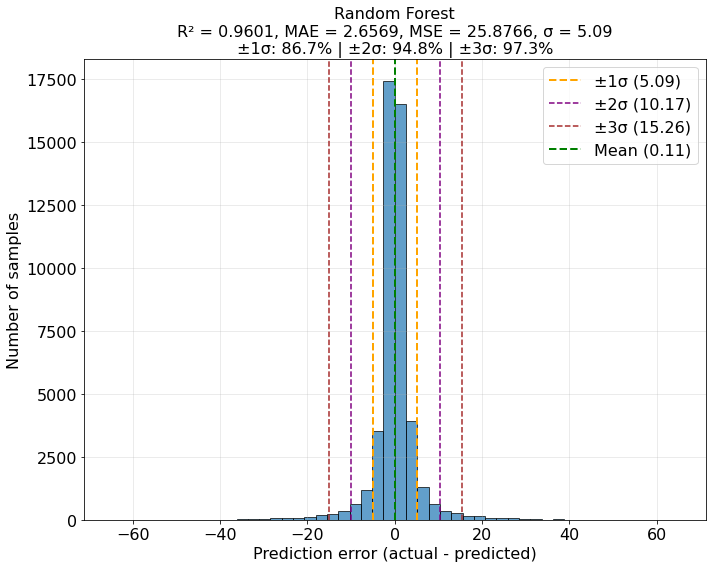

In [ ]:
# Visualization of results with histograms and standard deviation
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

for name, res in results.items():
    y_pred_test = res['model'].predict(X_test)
    
    # Calculate prediction errors
    errors = y_test - y_pred_test
    
    # Calculate standard deviation
    std_dev = errors.std()
    mean_error = errors.mean()
    
    # Calculate the percentage of data within the intervals
    within_1sigma = np.sum(np.abs(errors - mean_error) <= std_dev) / len(errors) * 100
    within_2sigma = np.sum(np.abs(errors - mean_error) <= 2*std_dev) / len(errors) * 100
    within_3sigma = np.sum(np.abs(errors - mean_error) <= 3*std_dev) / len(errors) * 100
    
    # Error histogram
    ax.hist(errors, bins=50, alpha=0.7, edgecolor='black')
    # ax.axvline(x=0, color='r', linestyle='--', lw=2, label='Ideal model')
    
    # Mark standard deviations
    ax.axvline(x=mean_error + std_dev, color='orange', linestyle='--', lw=2, label=f'±1σ ({std_dev:.2f})')
    ax.axvline(x=mean_error - std_dev, color='orange', linestyle='--', lw=2)
    
    ax.axvline(x=mean_error + 2*std_dev, color='purple', linestyle='--', lw=1.5, label=f'±2σ ({2*std_dev:.2f})')
    ax.axvline(x=mean_error - 2*std_dev, color='purple', linestyle='--', lw=1.5)
    
    ax.axvline(x=mean_error + 3*std_dev, color='brown', linestyle='--', lw=1.5, label=f'±3σ ({3*std_dev:.2f})')
    ax.axvline(x=mean_error - 3*std_dev, color='brown', linestyle='--', lw=1.5)
    
    ax.axvline(x=mean_error, color='green', linestyle='--', lw=2, label=f'Mean ({mean_error:.2f})')
    
    ax.set_xlabel('Prediction error (actual - predicted)', fontsize=FONT_SIZE)
    ax.set_ylabel('Number of samples', fontsize=FONT_SIZE)
    
    # Title with percentages
    title = f'{name}\nR² = {res["test_r2"]:.4f}, MAE = {res["test_mae"]:.4f}, MSE = {res["test_mse"]:.4f}, σ = {std_dev:.2f}\n'
    title += f'±1σ: {within_1sigma:.1f}% | ±2σ: {within_2sigma:.1f}% | ±3σ: {within_3sigma:.1f}%'
    ax.set_title(title, fontsize=FONT_SIZE)
    
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=FONT_SIZE)
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.show()

# On the validation set

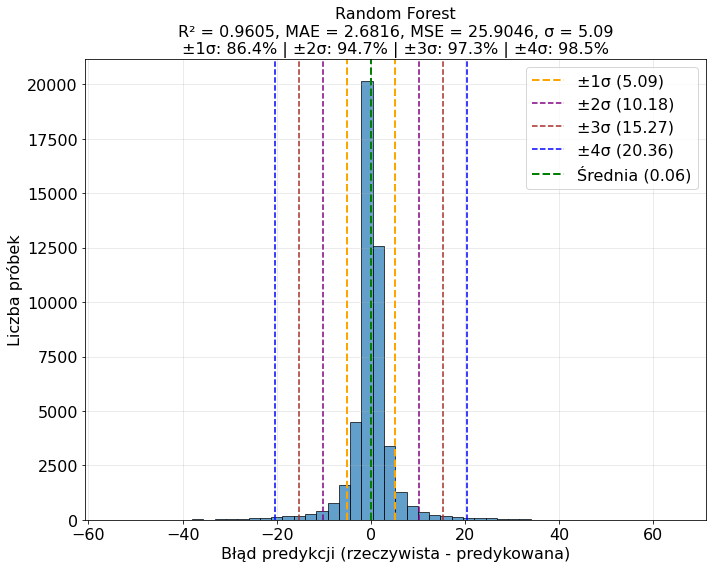

In [ ]:
# Visualization of results with histograms and standard deviation
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

for name, res in results.items():
    y_pred_val = res['model'].predict(X_val)
    
    # Calculate prediction errors
    errors = y_val - y_pred_val
    
    # Calculate standard deviation
    std_dev = errors.std()
    mean_error = errors.mean()
    
    # Calculate the percentage of data within the intervals
    within_1sigma = np.sum(np.abs(errors - mean_error) <= std_dev) / len(errors) * 100
    within_2sigma = np.sum(np.abs(errors - mean_error) <= 2*std_dev) / len(errors) * 100
    within_3sigma = np.sum(np.abs(errors - mean_error) <= 3*std_dev) / len(errors) * 100
    within_4sigma = np.sum(np.abs(errors - mean_error) <= 4*std_dev) / len(errors) * 100
    
    # Error histogram
    ax.hist(errors, bins=50, alpha=0.7, edgecolor='black')
    # ax.axvline(x=0, color='r', linestyle='--', lw=2, label='Ideal model')
    
    # Mark standard deviations
    ax.axvline(x=mean_error + std_dev, color='orange', linestyle='--', lw=2, label=f'±1σ ({std_dev:.2f})')
    ax.axvline(x=mean_error - std_dev, color='orange', linestyle='--', lw=2)
    
    ax.axvline(x=mean_error + 2*std_dev, color='purple', linestyle='--', lw=1.5, label=f'±2σ ({2*std_dev:.2f})')
    ax.axvline(x=mean_error - 2*std_dev, color='purple', linestyle='--', lw=1.5)
    
    ax.axvline(x=mean_error + 3*std_dev, color='brown', linestyle='--', lw=1.5, label=f'±3σ ({3*std_dev:.2f})')
    ax.axvline(x=mean_error - 3*std_dev, color='brown', linestyle='--', lw=1.5)
    
    ax.axvline(x=mean_error + 4*std_dev, color='blue', linestyle='--', lw=1.5, label=f'±4σ ({4*std_dev:.2f})')
    ax.axvline(x=mean_error - 4*std_dev, color='blue', linestyle='--', lw=1.5)
    
    ax.axvline(x=mean_error, color='green', linestyle='--', lw=2, label=f'Mean ({mean_error:.2f})')
    
    ax.set_xlabel('Prediction error (actual - predicted)', fontsize=FONT_SIZE)
    ax.set_ylabel('Number of samples', fontsize=FONT_SIZE)
    
    # Title with percentages
    title = f'{name}\nR² = {res["val_r2"]:.4f}, MAE = {res["val_mae"]:.4f}, MSE = {res["val_mse"]:.4f}, σ = {std_dev:.2f}\n'
    title += f'±1σ: {within_1sigma:.1f}% | ±2σ: {within_2sigma:.1f}% | ±3σ: {within_3sigma:.1f}% | ±4σ: {within_4sigma:.1f}%'
    ax.set_title(title, fontsize=FONT_SIZE)
    
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=FONT_SIZE)
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.show()


## Validation - logarithmic scale

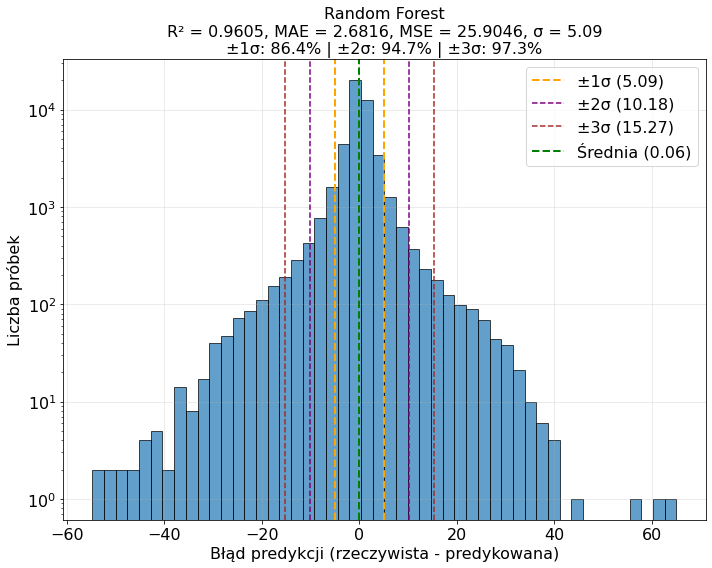

In [ ]:
# Visualization of results with histograms and standard deviation - logarithmic scale
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

for name, res in results.items():
    y_pred_val = res['model'].predict(X_val)
    
    # Calculate prediction errors
    errors = y_val - y_pred_val
    
    # Calculate standard deviation
    std_dev = errors.std()
    mean_error = errors.mean()
    
    # Calculate the percentage of data within the intervals
    within_1sigma = np.sum(np.abs(errors - mean_error) <= std_dev) / len(errors) * 100
    within_2sigma = np.sum(np.abs(errors - mean_error) <= 2*std_dev) / len(errors) * 100
    within_3sigma = np.sum(np.abs(errors - mean_error) <= 3*std_dev) / len(errors) * 100
    
    # Error histogram
    ax.hist(errors, bins=50, alpha=0.7, edgecolor='black')
    # ax.axvline(x=0, color='r', linestyle='--', lw=2, label='Ideal model')
    
    # Mark standard deviations
    ax.axvline(x=mean_error + std_dev, color='orange', linestyle='--', lw=2, label=f'±1σ ({std_dev:.2f})')
    ax.axvline(x=mean_error - std_dev, color='orange', linestyle='--', lw=2)
    
    ax.axvline(x=mean_error + 2*std_dev, color='purple', linestyle='--', lw=1.5, label=f'±2σ ({2*std_dev:.2f})')
    ax.axvline(x=mean_error - 2*std_dev, color='purple', linestyle='--', lw=1.5)
    
    ax.axvline(x=mean_error + 3*std_dev, color='brown', linestyle='--', lw=1.5, label=f'±3σ ({3*std_dev:.2f})')
    ax.axvline(x=mean_error - 3*std_dev, color='brown', linestyle='--', lw=1.5)
    
    ax.axvline(x=mean_error, color='green', linestyle='--', lw=2, label=f'Mean ({mean_error:.2f})')
    
    ax.set_xlabel('Prediction error (actual - predicted)', fontsize=FONT_SIZE)
    ax.set_ylabel('Number of samples', fontsize=FONT_SIZE)
    ax.set_yscale('log')
    
    # Title with percentages
    title = f'{name}\nR² = {res["val_r2"]:.4f}, MAE = {res["val_mae"]:.4f}, MSE = {res["val_mse"]:.4f}, σ = {std_dev:.2f}\n'
    title += f'±1σ: {within_1sigma:.1f}% | ±2σ: {within_2sigma:.1f}% | ±3σ: {within_3sigma:.1f}%'
    ax.set_title(title, fontsize=FONT_SIZE)
    
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=FONT_SIZE)
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.show()


# Tails

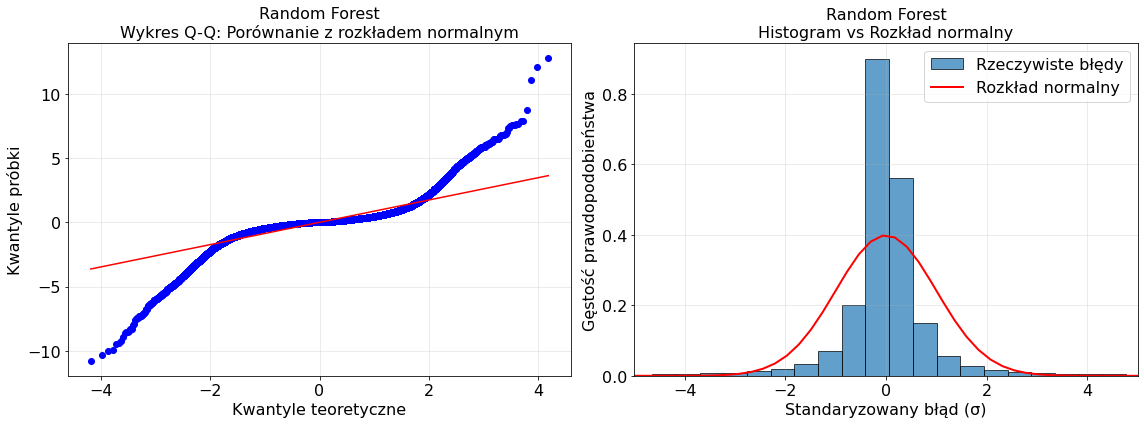


ANALIZA OGONÓW ROZKŁADU - Random Forest
Kurtoza: 15.4301
  (0 = rozkład normalny, >0 = grubsze ogony, <0 = cieńsze ogony)
Skośność: -0.1234
  (0 = symetryczny, >0 = prawy ogon dłuższy, <0 = lewy ogon dłuższy)

Próbki w 'ogonach' rozkładu:
  Poza ±2σ: 5.26% (normalny: 4.6%)
  Poza ±3σ: 2.73% (normalny: 0.3%)
  Poza ±4σ: 1.46% (normalny: 0.006%)

Test normalności Shapiro-Wilk:
  Statystyka: 0.738243
  p-wartość: 0.000000e+00
  Wniosek: Rozkład NIE jest normalny (α=0.05)


In [ ]:
# Analysis of heavy-tailed distribution on the validation set
from scipy import stats

for name, res in results.items():
    y_pred_val = res['model'].predict(X_val)
    errors = y_val - y_pred_val
    
    # Standardize the errors
    errors_standardized = (errors - errors.mean()) / errors.std()
    
    # Prepare the comparison figure
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Plot 1: Q-Q plot - comparison with the normal distribution
    stats.probplot(errors_standardized, dist="norm", plot=axes[0])
    axes[0].set_title(f'{name}\nQ-Q plot: Comparison with the normal distribution', fontsize=FONT_SIZE)
    axes[0].set_xlabel('Theoretical quantiles', fontsize=FONT_SIZE)
    axes[0].set_ylabel('Sample quantiles', fontsize=FONT_SIZE)
    axes[0].grid(True, alpha=0.3)
    axes[0].tick_params(axis='both', which='major', labelsize=FONT_SIZE)
    
    # Plot 2: Compare the histogram with the normal distribution
    axes[1].hist(errors_standardized, bins=50, density=True, alpha=0.7, 
                 edgecolor='black', label='Actual errors')
    
    # Overlay the theoretical normal distribution
    x_range = np.linspace(errors_standardized.min(), errors_standardized.max(), 100)
    normal_pdf = stats.norm.pdf(x_range, 0, 1)
    axes[1].plot(x_range, normal_pdf, 'r-', lw=2, label='Normal distribution')
    
    axes[1].set_xlabel('Standardized error (σ)', fontsize=FONT_SIZE)
    axes[1].set_ylabel('Probability density', fontsize=FONT_SIZE)
    axes[1].set_title(f'{name}\nHistogram vs normal distribution', fontsize=FONT_SIZE)
    axes[1].legend(fontsize=FONT_SIZE)
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xlim(-5, 5)
    axes[1].tick_params(axis='both', which='major', labelsize=FONT_SIZE)
    
    plt.tight_layout()
    plt.show()
    
    # Tail statistics
    print(f"\n{'='*60}")
    print(f"TAIL ANALYSIS - {name}")
    print('='*60)
    
    # Kurtosis (measure of tail thickness)
    kurtosis = stats.kurtosis(errors_standardized)
    print(f"Kurtosis: {kurtosis:.4f}")
    print(f"  (0 = normal distribution, >0 = heavier tails, <0 = lighter tails)")
    
    # Skewness
    skewness = stats.skew(errors_standardized)
    print(f"Skewness: {skewness:.4f}")
    print(f"  (0 = symmetric, >0 = longer right tail, <0 = longer left tail)")
    
    # Percentage of samples in the tails
    beyond_2sigma = np.sum(np.abs(errors_standardized) > 2) / len(errors_standardized) * 100
    beyond_3sigma = np.sum(np.abs(errors_standardized) > 3) / len(errors_standardized) * 100
    beyond_4sigma = np.sum(np.abs(errors_standardized) > 4) / len(errors_standardized) * 100
    
    print(f"\nSamples in the distribution 'tails':")
    print(f"  Outside ±2σ: {beyond_2sigma:.2f}% (normal: 4.6%)")
    print(f"  Outside ±3σ: {beyond_3sigma:.2f}% (normal: 0.3%)")
    print(f"  Outside ±4σ: {beyond_4sigma:.2f}% (normal: 0.006%)")
    
    # Shapiro-Wilk normality test (sample max 5000)
    sample_for_test = errors_standardized[:5000] if len(errors_standardized) > 5000 else errors_standardized
    shapiro_stat, shapiro_p = stats.shapiro(sample_for_test)
    print(f"\nShapiro-Wilk normality test:")
    print(f"  Statistic: {shapiro_stat:.6f}")
    print(f"  p-value: {shapiro_p:.6e}")
    print(f"  Conclusion: {'Distribution is NOT normal' if shapiro_p < 0.05 else 'Distribution is normal'} (α=0.05)")


# Validation boxplots

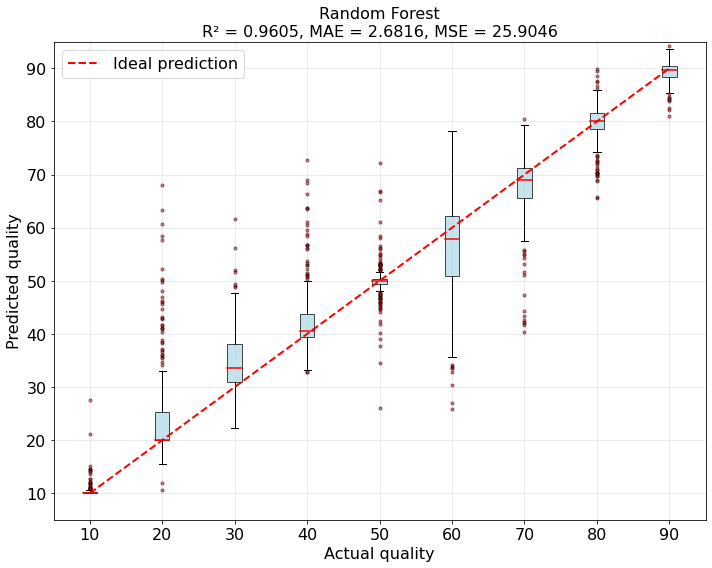

Plot saved as 'models_validation_comparison_boxplot_10percent.png'
Number of samples: 4753 (10% of 47539)


In [7]:
# Randomly select 10% of the validation set
sample_size = int(len(X_val) * 0.1)
sample_indices = np.random.choice(len(X_val), size=sample_size, replace=False)

X_val_sample = X_val.iloc[sample_indices]
y_val_sample = y_val.iloc[sample_indices]

# Visualize models on 10% of the validation data - boxplot
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

# Pre-compute unique qualities once - every 10
unique_qualities = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90])

for name, res in results.items():
    # Get predictions for the sample
    y_pred_val_model = res['model'].predict(X_val_sample)
    
    # Vectorized grouping - much faster than loop
    box_data = [y_pred_val_model[y_val_sample.values == quality] for quality in unique_qualities]
    
    # Create box plot with minimal features
    bp = ax.boxplot(box_data, positions=unique_qualities, widths=2, 
                            patch_artist=True, showfliers=True,
                            medianprops=dict(color='red', linewidth=1.5),
                            flierprops=dict(marker='o', markerfacecolor='red', markersize=3, alpha=0.5))
    
    # Vectorized styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    
    # Plot ideal line
    ax.plot(unique_qualities, unique_qualities, 'r--', lw=2, label='Ideal prediction')
    
    # Set labels and title
    ax.set_xlabel('Actual quality', fontsize=FONT_SIZE)
    ax.set_ylabel('Predicted quality', fontsize=FONT_SIZE)
    ax.set_title(f'{name}\nR² = {res["val_r2"]:.4f}, MAE = {res["val_mae"]:.4f}, MSE = {res["val_mse"]:.4f}', fontsize=FONT_SIZE)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=FONT_SIZE)
    ax.set_xlim(5, 95)
    ax.set_ylim(5, 95)
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.savefig('models_validation_comparison_boxplot_10percent.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Plot saved as 'models_validation_comparison_boxplot_10percent.png'")
print(f"Number of samples: {sample_size} (10% of {len(X_val)})")


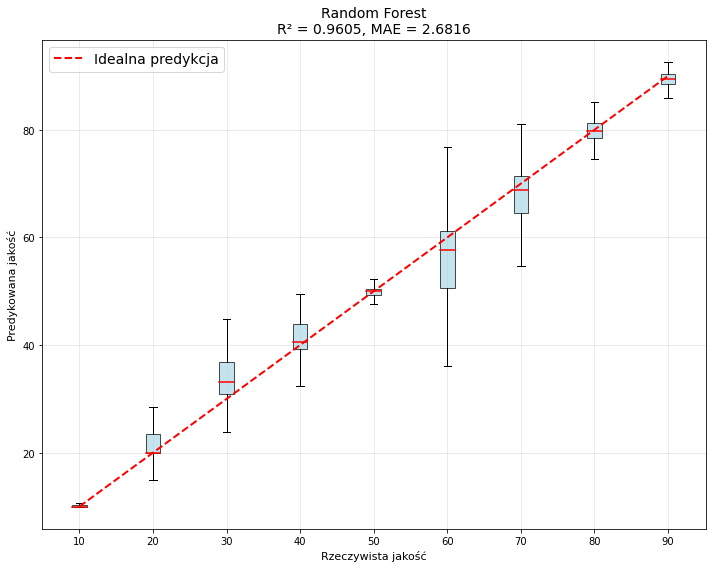

Wykres zapisany jako 'models_validation_comparison_boxplot_linear_10percent.png'
Liczba próbek: 4753 (10% z 47539)


In [ ]:
# Randomly select 10% of the validation set
sample_size = int(len(X_val) * 0.1)
sample_indices = np.random.choice(len(X_val), size=sample_size, replace=False)

X_val_sample = X_val.iloc[sample_indices]
y_val_sample = y_val.iloc[sample_indices]

# Visualize models on 10% of the validation data - linear scale
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

# Pre-compute unique qualities once - every 10
unique_qualities = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90])

for name, res in results.items():
    # Get predictions for the sample
    y_pred_val_model = res['model'].predict(X_val_sample)
    
    # Vectorized grouping - much faster than loop
    box_data = [y_pred_val_model[y_val_sample.values == quality] for quality in unique_qualities]
    
    # Create box plot with minimal features
    bp = ax.boxplot(box_data, positions=unique_qualities, widths=2, 
                            patch_artist=True, showfliers=False,
                            medianprops=dict(color='red', linewidth=1.5))
    
    # Vectorized styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    
    # Plot ideal line
    ax.plot(unique_qualities, unique_qualities, 'r--', lw=2, label='Ideal prediction')
    
    # Set labels and title
    ax.set_xlabel('Actual quality', fontsize=FONT_SIZE)
    ax.set_ylabel('Predicted quality', fontsize=FONT_SIZE)
    ax.set_title(f'{name}\nR² = {res["val_r2"]:.4f}, MAE = {res["val_mae"]:.4f}, MSE = {res["val_mse"]:.4f}', fontsize=FONT_SIZE)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=FONT_SIZE)
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.savefig('models_validation_comparison_boxplot_linear_10percent.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Plot saved as 'models_validation_comparison_boxplot_linear_10percent.png'")
print(f"Number of samples: {sample_size} (10% of {len(X_val)})")


# Test on JFIF (this person doesn't exist)

# Moved to ML-compression-tests

# Example: MAE = 2.5, MSE = 25

In [ ]:
errors_exact = np.array([15, 2, 2, 1, 1, 1, 1, 1, 0, 0])
mae_exact = np.mean(np.abs(errors_exact))
# Example where the actual quality is 50, so the predicted values are 50 - errors_exact; the choice does not change the MSE
mse_exact = mean_squared_error([50]*10, 50 - errors_exact)

print(f"Errors: {errors_exact}")
print(f"MAE = {mae_exact:.4f}")
print(f"MSE = {mse_exact:.4f}")
print(f"RMSE = {np.sqrt(mse_exact):.4f}")


Błędy: [15  2  2  1  1  1  1  1  0  0]
MAE = 2.4000
MSE = 23.8000
RMSE = 4.8785
